<h1>Feature Engineering on the flight dataset<h1>

In [2]:
import numpy as np
import pandas as pd

original = pd.read_csv("data.csv")
compition = pd.read_csv('train.csv').drop(columns = ["id"])
test  = pd.read_csv('test.csv')

train_df = pd.concat([original,compition])
test_df = pd.read_csv("test.csv")

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
df = train_df

In [4]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["satisfaction", "id"], errors="ignore")
y = df["satisfaction"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (663612, 21)
X_val: (165903, 21)
y_train: (663612,)
y_val: (165903,)


In [5]:
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,Female,Loyal Customer,57,Business travel,Eco,612,2,1,1,1,...,3,2,2,2,2,2,4,0,0.0,False
699631,Female,disloyal Customer,30,Business travel,Eco,862,2,2,2,3,...,4,4,2,5,4,2,4,24,34.0,False
699632,Male,Loyal Customer,49,Business travel,Business,3148,5,5,5,5,...,4,5,5,5,5,5,5,0,0.0,True
699633,Female,Loyal Customer,61,Business travel,Eco,679,5,2,2,2,...,4,5,4,5,5,5,1,0,0.0,True


<h1>Feature Engineering

In [6]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Separate target and features
y = train_df["satisfaction"].copy()

X = train_df.drop(
    columns=["satisfaction", "id"],
    errors="ignore"
).copy()

# Prepare competition test features
test_ids = test_df["id"].copy()

X_submission = test_df.drop(
    columns=["id", "satisfaction"],
    errors="ignore"
).copy()

# Ensure training and test features have identical columns and order
X_submission = X_submission.reindex(columns=X.columns)

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

num_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

# Split the training data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_submission.shape)

Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Numerical columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Training shape: (663612, 21)
Validation shape: (165903, 21)
Test shape: (299844, 21)


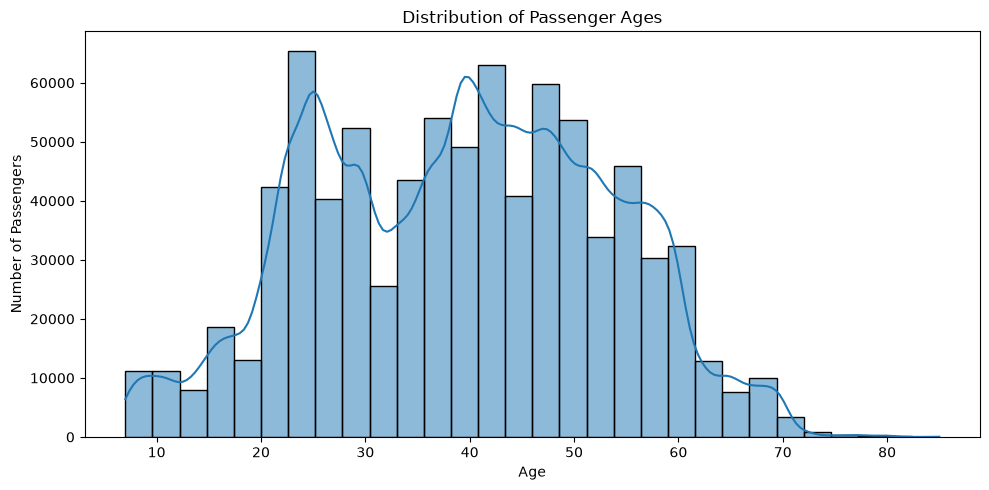

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check age distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd

age_bins = [0, 18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "0-18",
    "19-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

train_df["AgeGroup"] = pd.cut(
    train_df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print(train_df.groupby(
    "AgeGroup",
    observed=False
)["satisfaction"].value_counts().unstack(fill_value=0))

satisfaction   False   True 
AgeGroup                    
0-18           47384    8267
19-25          78909   34987
26-35         104176   57619
36-45          96849  110056
46-55          71733  106328
56-65          47699   47297
66+            15998    2213


In [9]:
service_columns = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness'
]

df['Satisfaction_Rate'] = (
    df[service_columns].mean(axis=1) / 5
) * 100

Satisfaction labels: <StringArray>
['false', 'true']
Length: 2, dtype: str
AgeGroup
0-18     0.0
19-25    0.0
26-35    0.0
36-45    0.0
46-55    0.0
56-65    0.0
66+      0.0
Name: satisfaction, dtype: float64


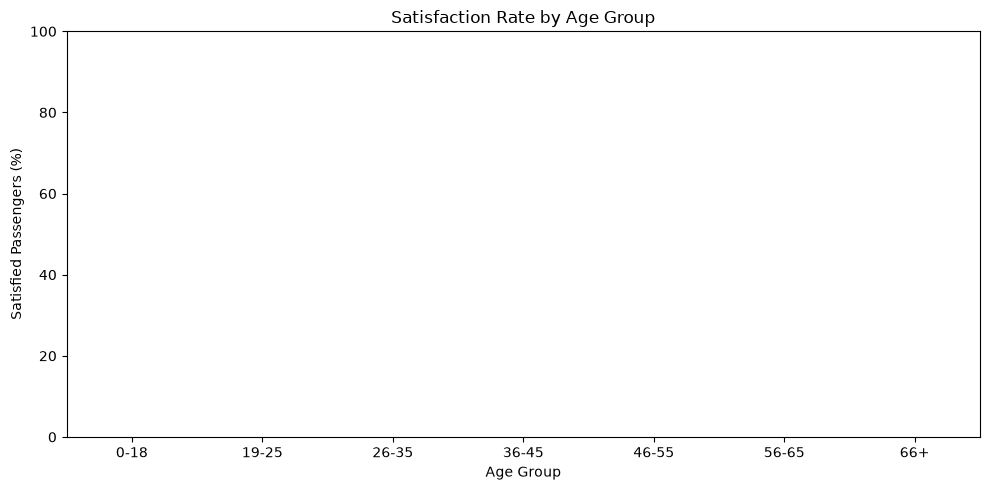

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Normalize target labels
satisfaction = train_df["satisfaction"].astype(str).str.strip().str.lower()

# Check the actual labels
print("Satisfaction labels:", satisfaction.unique())

# Create age groups
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = ["0-18", "19-25", "26-35", "36-45", "46-55", "56-65", "66+"]

train_df["AgeGroup"] = pd.cut(
    train_df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate the percentage of satisfied passengers in each age group
satisfied_rate = (
    satisfaction.eq("satisfied")
    .groupby(train_df["AgeGroup"], observed=False)
    .mean()
    .mul(100)
)

print(satisfied_rate)

# Visualize
plt.figure(figsize=(10, 5))
sns.barplot(x=satisfied_rate.index, y=satisfied_rate.values)

plt.title("Satisfaction Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Satisfied Passengers (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


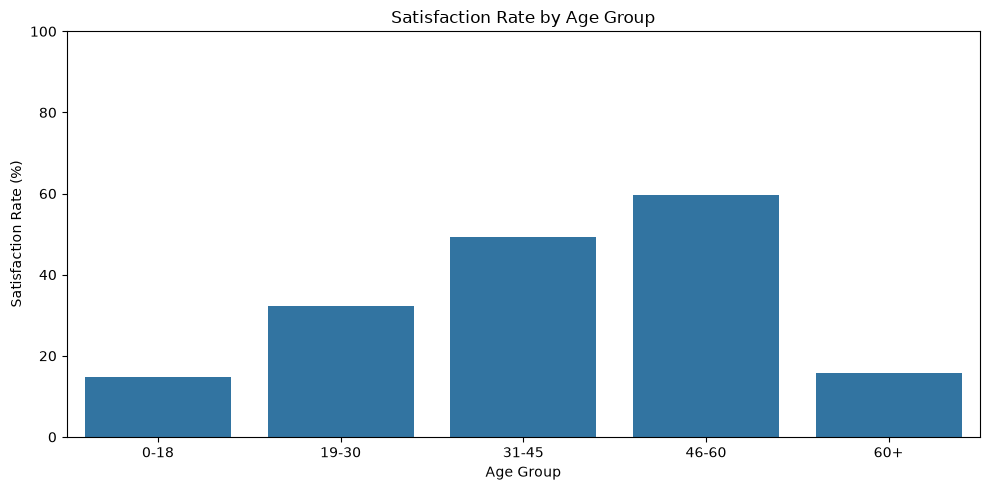

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 18, 30, 45, 60, 100],
    labels=['0-18', '19-30', '31-45', '46-60', '60+']
)

# 2. Calculate satisfaction rate for each age group
satisfaction_rate = (
    df.groupby('AgeGroup', observed=False)['satisfaction']
      .mean()
      .mul(100)
      .reset_index(name='SatisfactionRate')
)

# 3. Plot the satisfaction rate
plt.figure(figsize=(10, 5))

sns.barplot(
    data=satisfaction_rate,
    x='AgeGroup',
    y='SatisfactionRate'
)

plt.title('Satisfaction Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Satisfaction Rate (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


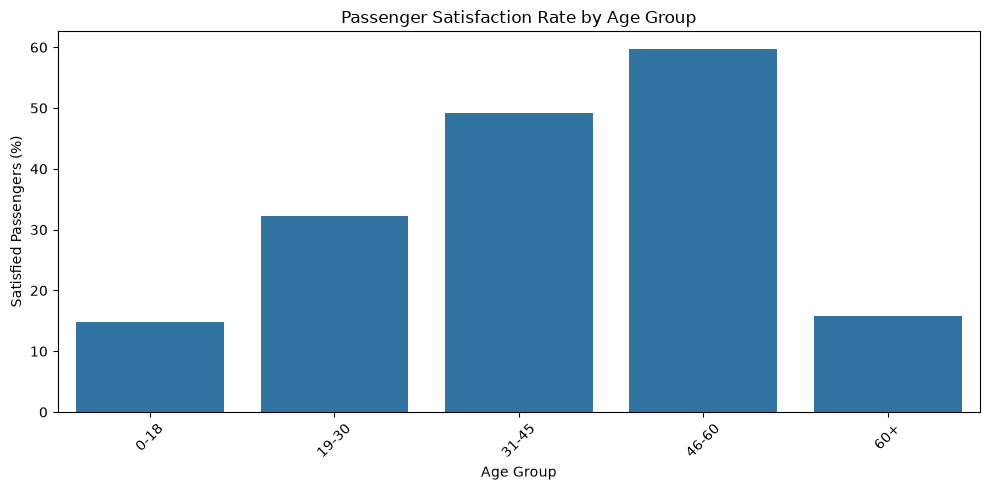

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=satisfaction_rate,
    x="AgeGroup",
    y="SatisfactionRate"
)

plt.title("Passenger Satisfaction Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Satisfied Passengers (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [13]:
df = train_df

In [14]:
train_df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction', 'AgeGroup', 'Satisfaction_Rate'],
      dtype='str')

In [15]:
import numpy as np
import pandas as pd

# Preserve the original dataset
df_fe = df.copy()

# Target column
target = 'satisfaction'

# Numerical service-rating features
service_columns = [
    'Inflight wifi service',
    'Departure/Arrival time convenient',
    'Ease of Online booking',
    'Gate location',
    'Food and drink',
    'Online boarding',
    'Seat comfort',
    'Inflight entertainment',
    'On-board service',
    'Leg room service',
    'Baggage handling',
    'Checkin service',
    'Cleanliness'
]

# Delay features
delay_columns = [
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes'
]

# Categorical features
categorical_columns = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

# Other numerical features
numeric_columns = [
    'Age',
    'Flight Distance'
]

print("Original shape:", df.shape)
print("Feature engineering shape:", df_fe.shape)

Original shape: (829515, 24)
Feature engineering shape: (829515, 24)


Service Quality Features

In [16]:
# Total score across all service-rating features
df_fe['Total_Service_Score'] = (
    df_fe[service_columns].sum(axis=1, min_count=1)
)

# Average service rating
df_fe['Service_Average'] = (
    df_fe[service_columns].mean(axis=1)
)

# Median service rating
df_fe['Service_Median'] = (
    df_fe[service_columns].median(axis=1)
)

# Lowest service rating
df_fe['Service_Min'] = (
    df_fe[service_columns].min(axis=1)
)

# Highest service rating
df_fe['Service_Max'] = (
    df_fe[service_columns].max(axis=1)
)

# Standard deviation of service ratings
df_fe['Service_Std'] = (
    df_fe[service_columns].std(axis=1)
)

# Difference between highest and lowest ratings
df_fe['Service_Range'] = (
    df_fe['Service_Max'] - df_fe['Service_Min']
)

# Number of service ratings available
df_fe['Service_Rating_Count'] = (
    df_fe[service_columns].notna().sum(axis=1)
)

Service category scores

In [17]:
# Digital and booking experience
digital_service_columns = [
    'Inflight wifi service',
    'Ease of Online booking',
    'Online boarding'
]

df_fe['Digital_Service_Score'] = (
    df_fe[digital_service_columns].mean(axis=1)
)

# Cabin experience
cabin_service_columns = [
    'Seat comfort',
    'Inflight entertainment',
    'Food and drink',
    'Leg room service'
]

df_fe['Cabin_Experience_Score'] = (
    df_fe[cabin_service_columns].mean(axis=1)
)

# Ground and operational service
ground_service_columns = [
    'Gate location',
    'Baggage handling',
    'Checkin service',
    'On-board service'
]

df_fe['Operational_Service_Score'] = (
    df_fe[ground_service_columns].mean(axis=1)
)

# Departure/arrival convenience
df_fe['Travel_Convenience_Score'] = (
    df_fe['Departure/Arrival time convenient']
)

# Cleanliness score
df_fe['Cleanliness_Score'] = df_fe['Cleanliness']

Counting High and low service values 

In [18]:
# Number of very low ratings
df_fe['Very_Low_Service_Count'] = (
    df_fe[service_columns].le(1).sum(axis=1)
)

# Number of low ratings
df_fe['Low_Service_Count'] = (
    df_fe[service_columns].le(2).sum(axis=1)
)

# Number of high ratings
df_fe['High_Service_Count'] = (
    df_fe[service_columns].ge(4).sum(axis=1)
)

# Number of maximum ratings
df_fe['Maximum_Service_Count'] = (
    df_fe[service_columns].eq(5).sum(axis=1)
)

# Proportion of high ratings among available ratings
df_fe['High_Service_Ratio'] = (
    df_fe[service_columns].ge(4).sum(axis=1)
    / df_fe['Service_Rating_Count'].replace(0, np.nan)
)

# Proportion of low ratings among available ratings
df_fe['Low_Service_Ratio'] = (
    df_fe[service_columns].le(2).sum(axis=1)
    / df_fe['Service_Rating_Count'].replace(0, np.nan)
)

Delay Features

In [19]:
departure = df_fe['Departure Delay in Minutes']
arrival = df_fe['Arrival Delay in Minutes']

# Departure delay
df_fe['Departure_Delay'] = departure

# Arrival delay
df_fe['Arrival_Delay'] = arrival

# Delay indicators
df_fe['Departure_Has_Delay'] = (
    departure > 0
).astype(int)

df_fe['Arrival_Has_Delay'] = (
    arrival > 0
).astype(int)

# Whether either recorded delay is positive
df_fe['Has_Delay'] = (
    (departure > 0) | (arrival > 0)
).astype(int)

# Whether both recorded delays are positive
df_fe['Both_Delays_Positive'] = (
    (departure > 0) & (arrival > 0)
).astype(int)

# Whether both recorded delays are zero
df_fe['No_Delay'] = (
    (departure == 0) & (arrival == 0)
).astype(int)

In [20]:
# Difference between arrival and departure delay
df_fe['Delay_Difference'] = arrival - departure

# Absolute difference between the two delays
df_fe['Absolute_Delay_Difference'] = (
    arrival - departure
).abs()

# Ratio of arrival delay to departure delay
df_fe['Arrival_Departure_Delay_Ratio'] = (
    arrival / departure.replace(0, np.nan)
)

# Arrival delay relative to departure delay
df_fe['Arrival_Departure_Delay_Relative'] = (
    (arrival - departure)
    / departure.replace(0, np.nan)
)

# Smaller of the two recorded delays
df_fe['Minimum_Delay'] = pd.concat(
    [departure, arrival], axis=1
).min(axis=1)

# Larger of the two recorded delays
df_fe['Maximum_Delay'] = pd.concat(
    [departure, arrival], axis=1
).max(axis=1)

# Sum of the two recorded delays
df_fe['Total_Recorded_Delay'] = departure + arrival

Categorical Delay

In [21]:
# Departure delay category
df_fe['Departure_Delay_Category'] = pd.cut(
    departure,
    bins=[-np.inf, 0, 15, 60, 180, np.inf],
    labels=[
        'No_Delay',
        'Short_Delay',
        'Moderate_Delay',
        'Long_Delay',
        'Very_Long_Delay'
    ]
)

# Arrival delay category
df_fe['Arrival_Delay_Category'] = pd.cut(
    arrival,
    bins=[-np.inf, 0, 15, 60, 180, np.inf],
    labels=[
        'No_Delay',
        'Short_Delay',
        'Moderate_Delay',
        'Long_Delay',
        'Very_Long_Delay'
    ]
)

Log transformed features 

In [22]:
# Only apply log1p to nonnegative delays
df_fe['Departure_Delay_Log'] = np.log1p(
    departure.clip(lower=0)
)

df_fe['Arrival_Delay_Log'] = np.log1p(
    arrival.clip(lower=0)
)

df_fe['Maximum_Delay_Log'] = np.log1p(
    df_fe['Maximum_Delay'].clip(lower=0)
)

Age categorical features 

In [23]:
df_fe['Age_Group'] = pd.cut(
    df_fe['Age'],
    bins=[0, 18, 30, 45, 60, np.inf],
    labels=[
        'Under_18',
        '18_29',
        '30_44',
        '45_59',
        '60_Plus'
    ],
    right=False
)

In [24]:
# Log-transformed flight distance
df_fe['Flight_Distance_Log'] = np.log1p(
    df_fe['Flight Distance'].clip(lower=0)
)

# Flight distance categories
df_fe['Flight_Distance_Category'] = pd.cut(
    df_fe['Flight Distance'],
    bins=[-np.inf, 500, 1500, 3000, np.inf],
    labels=[
        'Short',
        'Medium',
        'Long',
        'Very_Long'
    ]
)

In [25]:
# Loyal customer indicator
df_fe['Is_Loyal_Customer'] = (
    df_fe['Customer Type'] == 'Loyal Customer'
).astype(int)

# Business travel indicator
df_fe['Is_Business_Travel'] = (
    df_fe['Type of Travel'] == 'Business travel'
).astype(int)

# Personal travel indicator
df_fe['Is_Personal_Travel'] = (
    df_fe['Type of Travel'] == 'Personal Travel'
).astype(int)

# Business class indicator
df_fe['Is_Business_Class'] = (
    df_fe['Class'] == 'Business'
).astype(int)

# Economy class indicator
df_fe['Is_Eco_Class'] = (
    df_fe['Class'] == 'Eco'
).astype(int)

# Economy Plus indicator
df_fe['Is_Eco_Plus_Class'] = (
    df_fe['Class'] == 'Eco Plus'
).astype(int)

# Gender indicator
df_fe['Is_Female'] = (
    df_fe['Gender'] == 'Female'
).astype(int)

In [26]:
# Travel type and class
df_fe['Travel_Class_Interaction'] = (
    df_fe['Type of Travel'].astype('string')
    + '_'
    + df_fe['Class'].astype('string')
)

# Customer type and travel type
df_fe['Customer_Travel_Interaction'] = (
    df_fe['Customer Type'].astype('string')
    + '_'
    + df_fe['Type of Travel'].astype('string')
)

# Customer type and class
df_fe['Customer_Class_Interaction'] = (
    df_fe['Customer Type'].astype('string')
    + '_'
    + df_fe['Class'].astype('string')
)

# Travel type and age group
df_fe['Travel_Age_Interaction'] = (
    df_fe['Type of Travel'].astype('string')
    + '_'
    + df_fe['Age_Group'].astype('string')
)

In [27]:
# Wi-Fi and online boarding
df_fe['Wifi_Boarding_Interaction'] = (
    df_fe['Inflight wifi service']
    * df_fe['Online boarding']
)

# Wi-Fi and online booking
df_fe['Wifi_Booking_Interaction'] = (
    df_fe['Inflight wifi service']
    * df_fe['Ease of Online booking']
)

# Seat comfort and entertainment
df_fe['Seat_Entertainment_Interaction'] = (
    df_fe['Seat comfort']
    * df_fe['Inflight entertainment']
)

# Food and seat comfort
df_fe['Food_Seat_Interaction'] = (
    df_fe['Food and drink']
    * df_fe['Seat comfort']
)

# Seat comfort and legroom
df_fe['Seat_Legroom_Interaction'] = (
    df_fe['Seat comfort']
    * df_fe['Leg room service']
)

# Entertainment and food
df_fe['Entertainment_Food_Interaction'] = (
    df_fe['Inflight entertainment']
    * df_fe['Food and drink']
)

# Check-in and baggage handling
df_fe['Checkin_Baggage_Interaction'] = (
    df_fe['Checkin service']
    * df_fe['Baggage handling']
)

In [28]:
# Delay multiplied by overall service average
df_fe['Delay_Service_Interaction'] = (
    df_fe['Maximum_Delay']
    * df_fe['Service_Average']
)

# Delay multiplied by cabin experience
df_fe['Delay_Cabin_Interaction'] = (
    df_fe['Maximum_Delay']
    * df_fe['Cabin_Experience_Score']
)

# Delay multiplied by digital service
df_fe['Delay_Digital_Interaction'] = (
    df_fe['Maximum_Delay']
    * df_fe['Digital_Service_Score']
)

# Delay multiplied by flight distance
df_fe['Delay_Distance_Interaction'] = (
    df_fe['Maximum_Delay']
    * df_fe['Flight Distance']
)

In [29]:
# Age multiplied by flight distance
df_fe['Age_Distance_Interaction'] = (
    df_fe['Age']
    * df_fe['Flight Distance']
)

# Age multiplied by service average
df_fe['Age_Service_Interaction'] = (
    df_fe['Age']
    * df_fe['Service_Average']
)

# Distance multiplied by cabin experience
df_fe['Distance_Cabin_Interaction'] = (
    df_fe['Flight Distance']
    * df_fe['Cabin_Experience_Score']
)

In [30]:
# Squared age
df_fe['Age_Squared'] = df_fe['Age'] ** 2

# Squared flight distance
df_fe['Flight_Distance_Squared'] = (
    df_fe['Flight Distance'] ** 2
)

# Squared service average
df_fe['Service_Average_Squared'] = (
    df_fe['Service_Average'] ** 2
)

# Squared maximum delay
df_fe['Maximum_Delay_Squared'] = (
    df_fe['Maximum_Delay'] ** 2
)

In [31]:
from sklearn.preprocessing import PolynomialFeatures

interaction_columns = [
    'Age',
    'Flight Distance',
    'Service_Average',
    'Digital_Service_Score',
    'Cabin_Experience_Score',
    'Maximum_Delay'
]

poly = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

# Fit on training data only in a real ML pipeline
X_interactions = poly.fit_transform(
    df_fe[interaction_columns]
)

interaction_feature_names = poly.get_feature_names_out(
    interaction_columns
)

X_interactions = pd.DataFrame(
    X_interactions,
    columns=interaction_feature_names,
    index=df_fe.index
)

# Keep only the newly generated interaction terms
new_interaction_columns = [
    col for col in X_interactions.columns
    if ' ' in col
]

df_fe[new_interaction_columns] = (
    X_interactions[new_interaction_columns]
)

In [32]:
# Difference between each service rating and the passenger's average
for col in service_columns:
    df_fe[f'{col}_Deviation'] = (
        df_fe[col] - df_fe['Service_Average']
    )

# Difference between digital and cabin service scores
df_fe['Digital_Cabin_Difference'] = (
    df_fe['Digital_Service_Score']
    - df_fe['Cabin_Experience_Score']
)

# Difference between cabin and operational scores
df_fe['Cabin_Operational_Difference'] = (
    df_fe['Cabin_Experience_Score']
    - df_fe['Operational_Service_Score']
)

# Difference between digital and operational scores
df_fe['Digital_Operational_Difference'] = (
    df_fe['Digital_Service_Score']
    - df_fe['Operational_Service_Score']
)

H

In [33]:
# Missing indicators for all original features
original_feature_columns = [
    col for col in df.columns
    if col != target
]

for col in original_feature_columns:
    if df[col].isna().any():
        df_fe[f'{col}_Was_Missing'] = (
            df[col].isna().astype(int)
        )

In [34]:
print("Original dataset shape:", df.shape)
print("Engineered dataset shape:", df_fe.shape)

print("\nNew features created:")
new_features = [
    col for col in df_fe.columns
    if col not in df.columns
]

print(new_features)

print("\nNumber of new features:", len(new_features))

Original dataset shape: (829515, 24)
Engineered dataset shape: (829515, 126)

New features created:
['Total_Service_Score', 'Service_Average', 'Service_Median', 'Service_Min', 'Service_Max', 'Service_Std', 'Service_Range', 'Service_Rating_Count', 'Digital_Service_Score', 'Cabin_Experience_Score', 'Operational_Service_Score', 'Travel_Convenience_Score', 'Cleanliness_Score', 'Very_Low_Service_Count', 'Low_Service_Count', 'High_Service_Count', 'Maximum_Service_Count', 'High_Service_Ratio', 'Low_Service_Ratio', 'Departure_Delay', 'Arrival_Delay', 'Departure_Has_Delay', 'Arrival_Has_Delay', 'Has_Delay', 'Both_Delays_Positive', 'No_Delay', 'Delay_Difference', 'Absolute_Delay_Difference', 'Arrival_Departure_Delay_Ratio', 'Arrival_Departure_Delay_Relative', 'Minimum_Delay', 'Maximum_Delay', 'Total_Recorded_Delay', 'Departure_Delay_Category', 'Arrival_Delay_Category', 'Departure_Delay_Log', 'Arrival_Delay_Log', 'Maximum_Delay_Log', 'Age_Group', 'Flight_Distance_Log', 'Flight_Distance_Category',

In [35]:
numeric_fe = df_fe.select_dtypes(include='number')

print(
    "Infinite values:",
    np.isinf(numeric_fe.to_numpy()).sum()
)

Infinite values: 0


In [36]:
df_fe = df_fe.replace([np.inf, -np.inf], np.nan)

In [54]:
a = df_fe.columns.tolist
a

<bound method IndexOpsMixin.tolist of Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location',
       ...
       'Inflight entertainment_Deviation', 'On-board service_Deviation',
       'Leg room service_Deviation', 'Baggage handling_Deviation',
       'Checkin service_Deviation', 'Cleanliness_Deviation',
       'Digital_Cabin_Difference', 'Cabin_Operational_Difference',
       'Digital_Operational_Difference',
       'Arrival Delay in Minutes_Was_Missing'],
      dtype='str', length=126)>

In [37]:
from sklearn.model_selection import train_test_split

# Separate target and features
X = df_fe.drop(columns=['satisfaction'])
y = df_fe['satisfaction'].copy()

# Split before fitting any learned preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (663612, 125)
Testing shape: (165903, 125)


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    classification_report
)

# Identify columns by dtype
numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'scaler',
        StandardScaler()
    )
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='most_frequent')
    ),
    (
        'encoder',
        OneHotEncoder(handle_unknown='ignore')
    )
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    (
        'numerical',
        numerical_pipeline,
        numerical_features
    ),
    (
        'categorical',
        categorical_pipeline,
        categorical_features
    )
])

# Full model
model = Pipeline([
    (
        'preprocessor',
        preprocessor
    ),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Train
model.fit(X_train, y_train)

# Predict class probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Predict classes
y_pred = model.predict(X_test)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob)
)

print(
    classification_report(y_test, y_pred)
)

ROC-AUC: 0.9501955873731608
              precision    recall  f1-score   support

       False       0.91      0.92      0.92     92550
        True       0.90      0.89      0.90     73353

    accuracy                           0.91    165903
   macro avg       0.91      0.91      0.91    165903
weighted avg       0.91      0.91      0.91    165903



In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    classification_report
)

# Identify columns by dtype
numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'scaler',
        StandardScaler()
    )
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='most_frequent')
    ),
    (
        'encoder',
        OneHotEncoder(handle_unknown='ignore')
    )
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    (
        'numerical',
        numerical_pipeline,
        numerical_features
    ),
    (
        'categorical',
        categorical_pipeline,
        categorical_features
    )
])

# Full model
model = Pipeline([
    (
        'preprocessor',
        preprocessor
    ),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

# Train
model.fit(X_train, y_train)

# Predict class probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Predict classes
y_pred = model.predict(X_test)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob)
)

print(
    classification_report(y_test, y_pred)
)

ROC-AUC: 0.9501955873731608
              precision    recall  f1-score   support

       False       0.91      0.92      0.92     92550
        True       0.90      0.89      0.90     73353

    accuracy                           0.91    165903
   macro avg       0.91      0.91      0.91    165903
weighted avg       0.91      0.91      0.91    165903



In [40]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Original features only
X_baseline = df.drop(columns=['satisfaction'])

y_baseline = df['satisfaction']

X_base_train, X_base_test, y_base_train, y_base_test = (
    train_test_split(
        X_baseline,
        y_baseline,
        test_size=0.2,
        random_state=42,
        stratify=y_baseline
    )
)

# Baseline column types
base_numeric = X_base_train.select_dtypes(
    include=['number']
).columns.tolist()

base_categorical = X_base_train.select_dtypes(
    include=['object', 'category', 'bool', 'string']
).columns.tolist()

# Baseline preprocessing
base_preprocessor = ColumnTransformer([
    (
        'numerical',
        clone(numerical_pipeline),
        base_numeric
    ),
    (
        'categorical',
        clone(categorical_pipeline),
        base_categorical
    )
])

baseline_model = Pipeline([
    ('preprocessor', base_preprocessor),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

In [41]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Baseline features
baseline_scores = cross_val_score(
    baseline_model,
    X_base_train,
    y_base_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

# Engineered features
engineered_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print(
    "Baseline ROC-AUC:",
    baseline_scores.mean(),
    "+/-",
    baseline_scores.std()
)

print(
    "Engineered ROC-AUC:",
    engineered_scores.mean(),
    "+/-",
    engineered_scores.std()
)

print(
    "Difference:",
    engineered_scores.mean() - baseline_scores.mean()
)

Baseline ROC-AUC: 0.9219683063522564 +/- 0.0004535780089506708
Engineered ROC-AUC: 0.9508606108547916 +/- 0.0002750833103506597
Difference: 0.028892304502535215


In [42]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Separate features and target
X = df.drop(columns=['satisfaction']).copy()
y = df['satisfaction'].astype(int)

# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Convert categorical values to strings for consistent processing
for col in categorical_cols:
    X[col] = X[col].fillna('Missing').astype(str)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Categorical columns:", categorical_cols)

Training shape: (663612, 23)
Testing shape: (165903, 23)
Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'AgeGroup']


In [43]:
from catboost import CatBoostClassifier

# Initialize the model
cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=7,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

# Train the model
cat_model.fit(
    X_train,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100,
    verbose=100
)

# Predictions
cat_pred = cat_model.predict(X_test).ravel().astype(int)
cat_proba = cat_model.predict_proba(X_test)[:, 1]

print("\nCatBoost Results")
print("----------------")

print("Accuracy:", accuracy_score(y_test, cat_pred))
print("Precision:", precision_score(y_test, cat_pred, zero_division=0))
print("Recall:", recall_score(y_test, cat_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, cat_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, cat_proba))

print("\nClassification Report:")
print(classification_report(y_test, cat_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, cat_pred))

0:	test: 0.9431283	best: 0.9431283 (0)	total: 571ms	remaining: 9m 30s
100:	test: 0.9604341	best: 0.9604341 (100)	total: 39s	remaining: 5m 46s
200:	test: 0.9621661	best: 0.9621661 (200)	total: 1m 16s	remaining: 5m 4s
300:	test: 0.9629515	best: 0.9629515 (300)	total: 1m 54s	remaining: 4m 25s
400:	test: 0.9633572	best: 0.9633572 (400)	total: 2m 34s	remaining: 3m 51s
500:	test: 0.9635964	best: 0.9635964 (500)	total: 3m 14s	remaining: 3m 13s
600:	test: 0.9637605	best: 0.9637605 (600)	total: 3m 52s	remaining: 2m 34s
700:	test: 0.9639001	best: 0.9639001 (700)	total: 4m 30s	remaining: 1m 55s
800:	test: 0.9639951	best: 0.9639951 (800)	total: 5m 7s	remaining: 1m 16s
900:	test: 0.9640625	best: 0.9640636 (898)	total: 5m 44s	remaining: 37.9s
999:	test: 0.9641258	best: 0.9641258 (999)	total: 6m 22s	remaining: 0us

bestTest = 0.9641258161
bestIteration = 999


CatBoost Results
----------------
Accuracy: 0.9312067895095327
Precision: 0.9322883224923927
Recall: 0.9105421727809361
F1 Score: 0.9212869409

In [44]:
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=['number', 'bool']
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Create the complete pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

# Train the model
xgb_pipeline.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_pipeline.predict(X_test)
xgb_proba = xgb_pipeline.predict_proba(X_test)[:, 1]

print("\nXGBoost Results")
print("----------------")

print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))


XGBoost Results
----------------
Accuracy: 0.9307306076442259
Precision: 0.9320686716862
Recall: 0.9096287813722683
F1 Score: 0.9207120187663861
ROC-AUC: 0.9638499833435711

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     92550
           1       0.93      0.91      0.92     73353

    accuracy                           0.93    165903
   macro avg       0.93      0.93      0.93    165903
weighted avg       0.93      0.93      0.93    165903

Confusion Matrix:
[[87687  4863]
 [ 6629 66724]]


In [45]:
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=['number', 'bool']
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

# Create the complete pipeline
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])

# Train the model
xgb_pipeline.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_pipeline.predict(X_test)
xgb_proba = xgb_pipeline.predict_proba(X_test)[:, 1]

print("\nXGBoost Results")
print("----------------")

print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall:", recall_score(y_test, xgb_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, xgb_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))


XGBoost Results
----------------
Accuracy: 0.9307306076442259
Precision: 0.9320686716862
Recall: 0.9096287813722683
F1 Score: 0.9207120187663861
ROC-AUC: 0.9638499833435711

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     92550
           1       0.93      0.91      0.92     73353

    accuracy                           0.93    165903
   macro avg       0.93      0.93      0.93    165903
weighted avg       0.93      0.93      0.93    165903

Confusion Matrix:
[[87687  4863]
 [ 6629 66724]]


In [46]:
results = pd.DataFrame({
    'Model': ['CatBoost', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, cat_pred),
        accuracy_score(y_test, xgb_pred)
    ],

    'Precision': [
        precision_score(y_test, cat_pred, zero_division=0),
        precision_score(y_test, xgb_pred, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, cat_pred, zero_division=0),
        recall_score(y_test, xgb_pred, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, cat_pred, zero_division=0),
        f1_score(y_test, xgb_pred, zero_division=0)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, cat_proba),
        roc_auc_score(y_test, xgb_proba)
    ]
})

results = results.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print(results.round(4))

      Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  CatBoost    0.9312     0.9323  0.9105    0.9213   0.9641
1   XGBoost    0.9307     0.9321  0.9096    0.9207   0.9638


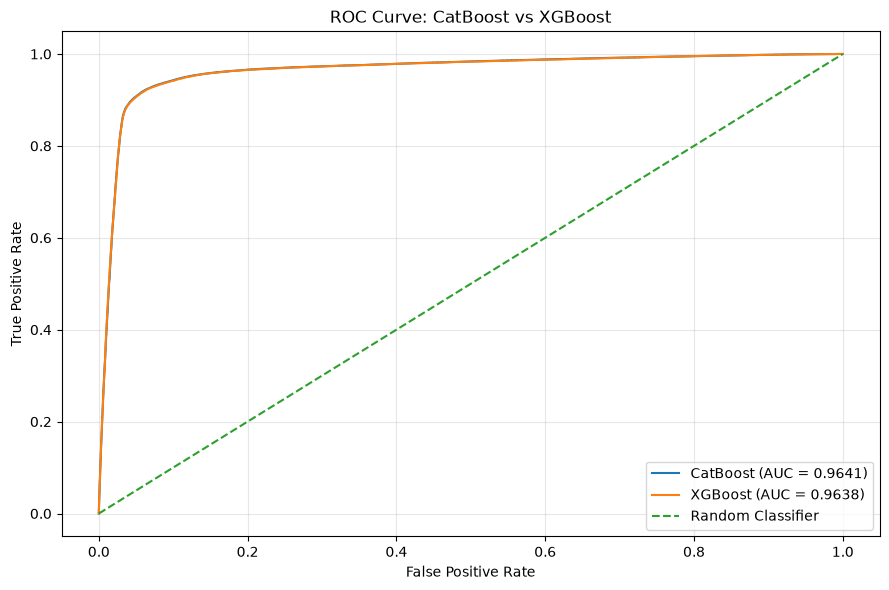

In [47]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curves
fpr_cat, tpr_cat, _ = roc_curve(y_test, cat_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)

auc_cat = auc(fpr_cat, tpr_cat)
auc_xgb = auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_cat,
    tpr_cat,
    label=f'CatBoost (AUC = {auc_cat:.4f})'
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGBoost (AUC = {auc_xgb:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: CatBoost vs XGBoost')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Get predicted probabilities from both models
cat_proba = cat_model.predict_proba(X_test)[:, 1]
xgb_proba = xgb_pipeline.predict_proba(X_test)[:, 1]

# Combine probabilities using soft voting
ensemble_proba = (cat_proba + xgb_proba) / 2

# Convert probabilities into binary predictions
ensemble_pred = (ensemble_proba >= 0.5).astype(int)

# Evaluate ensemble
print("CatBoost + XGBoost Ensemble")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, ensemble_pred):.4f}")
print(f"Precision: {precision_score(y_test, ensemble_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, ensemble_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, ensemble_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, ensemble_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, ensemble_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, ensemble_pred))

CatBoost + XGBoost Ensemble
Accuracy:  0.9311
Precision: 0.9324
Recall:    0.9102
F1 Score:  0.9212
ROC-AUC:   0.9642

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     92550
           1       0.93      0.91      0.92     73353

    accuracy                           0.93    165903
   macro avg       0.93      0.93      0.93    165903
weighted avg       0.93      0.93      0.93    165903

Confusion Matrix:
[[87709  4841]
 [ 6584 66769]]


In [50]:
unseen_df.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class'],
      dtype='str')

In [55]:
import pandas as pd
import numpy as np

# ==========================================
# 1. LOAD TEST DATA
# ==========================================

test_df = pd.read_csv("test.csv")

print("Test shape:", test_df.shape)
print("Test columns:", test_df.columns.tolist())


# ==========================================
# 2. FEATURE ENGINEERING FUNCTION
# ==========================================

def engineer_features(data):

    data = data.copy()

    # --------------------------------------
    # SERVICE RATING FEATURES
    # --------------------------------------

    service_columns = [
        'Inflight wifi service',
        'Departure/Arrival time convenient',
        'Ease of Online booking',
        'Gate location',
        'Food and drink',
        'Online boarding',
        'Seat comfort',
        'Inflight entertainment',
        'On-board service',
        'Leg room service',
        'Baggage handling',
        'Checkin service',
        'Cleanliness'
    ]

    # Check that the original service columns exist
    missing_service_cols = [
        col for col in service_columns
        if col not in data.columns
    ]

    if missing_service_cols:
        raise ValueError(
            f"Missing service columns: {missing_service_cols}"
        )

    # Ensure service ratings are numeric
    for col in service_columns:
        data[col] = pd.to_numeric(
            data[col],
            errors='coerce'
        )

    # Overall service statistics
    data['Total_Service_Score'] = (
        data[service_columns].sum(axis=1, min_count=1)
    )

    data['Service_Average'] = (
        data[service_columns].mean(axis=1)
    )

    data['Service_Median'] = (
        data[service_columns].median(axis=1)
    )

    data['Service_Min'] = (
        data[service_columns].min(axis=1)
    )

    data['Service_Max'] = (
        data[service_columns].max(axis=1)
    )

    data['Service_Std'] = (
        data[service_columns].std(axis=1)
    )

    data['Service_Range'] = (
        data['Service_Max'] - data['Service_Min']
    )

    data['Service_Rating_Count'] = (
        data[service_columns].count(axis=1)
    )

    # Percentage of the maximum possible service rating.
    # This is NOT the actual target satisfaction probability.
    data['Satisfaction_Rate'] = (
        data['Service_Average'] / 5
    ) * 100

    # Count low and high service ratings
    data['Low_Service_Rating_Count'] = (
        (data[service_columns] <= 2).sum(axis=1)
    )

    data['High_Service_Rating_Count'] = (
        (data[service_columns] >= 4).sum(axis=1)
    )

    data['Low_Service_Rating_Ratio'] = (
        data['Low_Service_Rating_Count']
        / data['Service_Rating_Count'].replace(0, np.nan)
    )

    data['High_Service_Rating_Ratio'] = (
        data['High_Service_Rating_Count']
        / data['Service_Rating_Count'].replace(0, np.nan)
    )

    # --------------------------------------
    # SERVICE CATEGORY SCORES
    # --------------------------------------

    digital_columns = [
        'Inflight wifi service',
        'Ease of Online booking',
        'Online boarding'
    ]

    cabin_columns = [
        'Food and drink',
        'Seat comfort',
        'Inflight entertainment',
        'On-board service',
        'Leg room service',
        'Cleanliness'
    ]

    operational_columns = [
        'Gate location',
        'Baggage handling',
        'Checkin service'
    ]

    convenience_columns = [
        'Departure/Arrival time convenient'
    ]

    data['Digital_Service_Score'] = (
        data[digital_columns].mean(axis=1)
    )

    data['Cabin_Service_Score'] = (
        data[cabin_columns].mean(axis=1)
    )

    data['Operational_Service_Score'] = (
        data[operational_columns].mean(axis=1)
    )

    data['Convenience_Service_Score'] = (
        data[convenience_columns].mean(axis=1)
    )

    # --------------------------------------
    # AGE FEATURES
    # --------------------------------------

    data['Age'] = pd.to_numeric(
        data['Age'],
        errors='coerce'
    )

    data['AgeGroup'] = pd.cut(
        data['Age'],
        bins=[0, 18, 30, 45, 60, 100],
        labels=['0-18', '19-30', '31-45', '46-60', '60+']
    )

    data['Age_Squared'] = data['Age'] ** 2

    data['Age_Missing'] = (
        data['Age'].isna().astype(int)
    )

    # --------------------------------------
    # FLIGHT DISTANCE FEATURES
    # --------------------------------------

    data['Flight Distance'] = pd.to_numeric(
        data['Flight Distance'],
        errors='coerce'
    )

    data['Flight_Distance_Log'] = np.log1p(
        data['Flight Distance'].clip(lower=0)
    )

    data['Flight_Distance_Squared'] = (
        data['Flight Distance'] ** 2
    )

    data['Flight_Distance_Bin'] = pd.cut(
        data['Flight Distance'],
        bins=[-np.inf, 500, 1000, 2000, 3000, np.inf],
        labels=[
            'Very Short',
            'Short',
            'Medium',
            'Long',
            'Very Long'
        ]
    )

    # --------------------------------------
    # DELAY FEATURES
    # --------------------------------------

    delay_columns = [
        'Departure Delay in Minutes',
        'Arrival Delay in Minutes'
    ]

    for col in delay_columns:
        data[col] = pd.to_numeric(
            data[col],
            errors='coerce'
        )

        data[col + '_Missing'] = (
            data[col].isna().astype(int)
        )

    departure = data['Departure Delay in Minutes']
    arrival = data['Arrival Delay in Minutes']

    data['Departure_Delay_Flag'] = (
        departure.fillna(0) > 0
    ).astype(int)

    data['Arrival_Delay_Flag'] = (
        arrival.fillna(0) > 0
    ).astype(int)

    data['Any_Delay_Flag'] = (
        (departure.fillna(0) > 0)
        | (arrival.fillna(0) > 0)
    ).astype(int)

    data['Delay_Difference'] = arrival - departure

    data['Delay_Ratio'] = (
        arrival / (departure + 1)
    )

    data['Delay_Min'] = data[delay_columns].min(axis=1)

    data['Delay_Max'] = data[delay_columns].max(axis=1)

    data['Total_Delay'] = data[delay_columns].sum(
        axis=1,
        min_count=1
    )

    data['Departure_Delay_Log'] = np.log1p(
        departure.clip(lower=0)
    )

    data['Arrival_Delay_Log'] = np.log1p(
        arrival.clip(lower=0)
    )

    data['Departure_Delay_Bin'] = pd.cut(
        departure,
        bins=[-np.inf, 0, 15, 60, np.inf],
        labels=['No Delay', 'Short Delay', 'Medium Delay', 'Long Delay']
    )

    data['Arrival_Delay_Bin'] = pd.cut(
        arrival,
        bins=[-np.inf, 0, 15, 60, np.inf],
        labels=['No Delay', 'Short Delay', 'Medium Delay', 'Long Delay']
    )

    # --------------------------------------
    # CATEGORICAL INTERACTIONS
    # --------------------------------------

    interaction_pairs = [
        ('Type of Travel', 'Class', 'Travel_Class_Interaction'),
        ('Customer Type', 'Type of Travel', 'Customer_Travel_Interaction'),
        ('Gender', 'Class', 'Gender_Class_Interaction')
    ]

    for col1, col2, new_col in interaction_pairs:
        data[new_col] = (
            data[col1].fillna('Missing').astype(str)
            + '_'
            + data[col2].fillna('Missing').astype(str)
        )

    # --------------------------------------
    # NUMERICAL INTERACTIONS
    # --------------------------------------

    data['WiFi_Boarding_Interaction'] = (
        data['Inflight wifi service']
        * data['Online boarding']
    )

    data['Seat_Entertainment_Interaction'] = (
        data['Seat comfort']
        * data['Inflight entertainment']
    )

    data['Delay_Service_Interaction'] = (
        data['Total_Delay']
        * data['Service_Average']
    )

    data['Age_Flight_Distance_Interaction'] = (
        data['Age']
        * data['Flight Distance']
    )

    # --------------------------------------
    # SERVICE DEVIATIONS
    # --------------------------------------

    for col in service_columns:
        data[col + '_Deviation'] = (
            data[col] - data['Service_Average']
        )

    # --------------------------------------
    # BINARY FEATURES
    # --------------------------------------

    data['Customer_Type_Loyal'] = (
        data['Customer Type'] == 'Loyal Customer'
    ).astype(int)

    data['Business_Travel'] = (
        data['Type of Travel'] == 'Business travel'
    ).astype(int)

    data['Business_Class'] = (
        data['Class'] == 'Business'
    ).astype(int)

    data['Gender_Male'] = (
        data['Gender'] == 'Male'
    ).astype(int)

    return data


# ==========================================
# 3. APPLY FEATURE ENGINEERING
# ==========================================

test_fe = engineer_features(test_df)

print("\nFeature engineering completed.")
print("Engineered test shape:", test_fe.shape)

print(
    test_fe[
        ['Age', 'AgeGroup', 'Satisfaction_Rate']
    ].head()
)

Test shape: (299844, 22)
Test columns: ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']

Feature engineering completed.
Engineered test shape: (299844, 83)
   Age AgeGroup  Satisfaction_Rate
0   25    19-30          61.538462
1   36    31-45          83.076923
2   45    31-45          75.384615
3   45    31-45          61.538462
4   34    31-45          35.384615


In [56]:
# Preserve the original test IDs
if 'id' in test_df.columns:
    test_ids = test_df['id'].copy()
else:
    test_ids = pd.Series(
        np.arange(len(test_df)),
        name='id'
    )

# Remove ID and target from prediction features
X_unseen = test_fe.drop(
    columns=['id', 'satisfaction'],
    errors='ignore'
).copy()

# Expected model input columns
expected_columns = X_train.columns.tolist()

# Identify missing columns
missing_columns = [
    col for col in expected_columns
    if col not in X_unseen.columns
]

# Identify extra columns that were not used in training
extra_columns = [
    col for col in X_unseen.columns
    if col not in expected_columns
]

print("Missing training features:", missing_columns)
print("Extra test features:", extra_columns)

if missing_columns:
    raise ValueError(
        "Some features used during training are still missing. "
        f"Missing columns: {missing_columns}. "
        "Recreate these features using the exact formulas used "
        "during training."
    )

# Use the same feature order as training
X_unseen = X_unseen[expected_columns].copy()

# Apply the same categorical conversion as training
for col in categorical_cols:
    if col in X_unseen.columns:
        X_unseen[col] = (
            X_unseen[col]
            .fillna('Missing')
            .astype(str)
        )

print("\nFeature alignment successful!")
print("Prediction input shape:", X_unseen.shape)

Missing training features: []
Extra test features: ['Total_Service_Score', 'Service_Average', 'Service_Median', 'Service_Min', 'Service_Max', 'Service_Std', 'Service_Range', 'Service_Rating_Count', 'Low_Service_Rating_Count', 'High_Service_Rating_Count', 'Low_Service_Rating_Ratio', 'High_Service_Rating_Ratio', 'Digital_Service_Score', 'Cabin_Service_Score', 'Operational_Service_Score', 'Convenience_Service_Score', 'Age_Squared', 'Age_Missing', 'Flight_Distance_Log', 'Flight_Distance_Squared', 'Flight_Distance_Bin', 'Departure Delay in Minutes_Missing', 'Arrival Delay in Minutes_Missing', 'Departure_Delay_Flag', 'Arrival_Delay_Flag', 'Any_Delay_Flag', 'Delay_Difference', 'Delay_Ratio', 'Delay_Min', 'Delay_Max', 'Total_Delay', 'Departure_Delay_Log', 'Arrival_Delay_Log', 'Departure_Delay_Bin', 'Arrival_Delay_Bin', 'Travel_Class_Interaction', 'Customer_Travel_Interaction', 'Gender_Class_Interaction', 'WiFi_Boarding_Interaction', 'Seat_Entertainment_Interaction', 'Delay_Service_Interaction'

In [57]:
# ==========================================
# 1. CATBOOST
# ==========================================

cat_proba_unseen = cat_model.predict_proba(
    X_unseen
)[:, 1]

cat_pred_unseen = cat_proba_unseen >= 0.5


# ==========================================
# 2. XGBOOST
# ==========================================

xgb_proba_unseen = xgb_pipeline.predict_proba(
    X_unseen
)[:, 1]

xgb_pred_unseen = xgb_proba_unseen >= 0.5


# ==========================================
# 3. COMBINED MODEL
# ==========================================

combined_proba_unseen = (
    cat_proba_unseen + xgb_proba_unseen
) / 2

combined_pred_unseen = (
    combined_proba_unseen >= 0.5
)


# ==========================================
# 4. CREATE CSV FILES
# ==========================================

cat_result = pd.DataFrame({
    'id': test_ids.to_numpy(),
    'satisfaction': cat_pred_unseen
})

xgb_result = pd.DataFrame({
    'id': test_ids.to_numpy(),
    'satisfaction': xgb_pred_unseen
})

combined_result = pd.DataFrame({
    'id': test_ids.to_numpy(),
    'satisfaction': combined_pred_unseen
})


# Save each result
cat_result.to_csv(
    'catboost_result.csv',
    index=False
)

xgb_result.to_csv(
    'xgboost_result.csv',
    index=False
)

combined_result.to_csv(
    'combined_result.csv',
    index=False
)


# ==========================================
# 5. VERIFY OUTPUTS
# ==========================================

print("\nAll result files generated successfully!")

for filename, result in [
    ('catboost_result.csv', cat_result),
    ('xgboost_result.csv', xgb_result),
    ('combined_result.csv', combined_result)
]:
    print(f"\n{filename}")
    print(result.head())
    print("Shape:", result.shape)
    print("Columns:", result.columns.tolist())


All result files generated successfully!

catboost_result.csv
       id  satisfaction
0  699635         False
1  699636          True
2  699637          True
3  699638         False
4  699639         False
Shape: (299844, 2)
Columns: ['id', 'satisfaction']

xgboost_result.csv
       id  satisfaction
0  699635         False
1  699636          True
2  699637          True
3  699638         False
4  699639         False
Shape: (299844, 2)
Columns: ['id', 'satisfaction']

combined_result.csv
       id  satisfaction
0  699635         False
1  699636          True
2  699637          True
3  699638         False
4  699639         False
Shape: (299844, 2)
Columns: ['id', 'satisfaction']
